<a href="https://colab.research.google.com/github/Ayushcodes-hub/FlowerVision/blob/main/notebooks/FlowerVision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install -U importlib_resources tensorflow-datasets


In [ ]:

# CELL 1: Import libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from sklearn.utils.class_weight import compute_class_weight

import tensorflow_datasets as tfds
import os
import random

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
NumPy: 2.4.6
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

# CELL 2: Reproducibility

SEED = 42

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

print("Random seed configured:", SEED)


Random seed configured: 42


In [ ]:

# CELL 3: Download and load dataset

!pip -q install tensorflow-datasets

import tensorflow_datasets as tfds

(train_raw, val_raw, test_raw), info = tfds.load(
    "tf_flowers",
    split=[
        "train[:70%]",
        "train[70%:85%]",
        "train[85%:]"
    ],
    as_supervised=True,
    with_info=True
)

CLASS_NAMES = info.features["label"].names
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)
print("Total images:", info.splits["train"].num_examples)
print("Training:", tf.data.experimental.cardinality(train_raw).numpy())
print("Validation:", tf.data.experimental.cardinality(val_raw).numpy())
print("Testing:", tf.data.experimental.cardinality(test_raw).numpy())


Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Number of classes: 5
Total images: 3670
Training: 2569
Validation: 551
Testing: 550


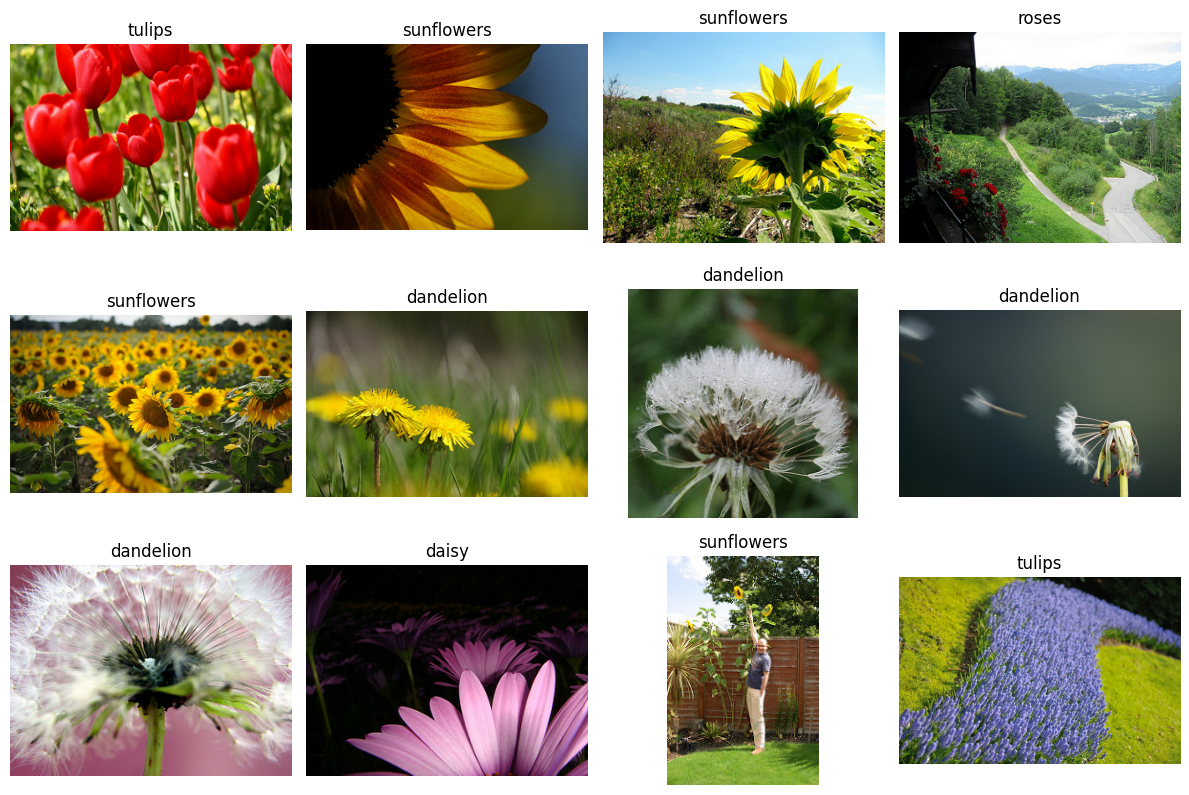

In [ ]:

# CELL 4: Display sample images

plt.figure(figsize=(12, 8))

for i, (image, label) in enumerate(train_raw.take(12)):
    plt.subplot(3, 4, i + 1)
    plt.imshow(image.numpy())
    plt.title(CLASS_NAMES[label.numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# CELL 5: Inspect image tensor

image, label = next(iter(train_raw))

print("Image shape:", image.shape)
print("Image datatype:", image.dtype)
print("Label:", label.numpy())
print("Flower:", CLASS_NAMES[label.numpy()])

print("Minimum pixel value:", tf.reduce_min(image).numpy())
print("Maximum pixel value:", tf.reduce_max(image).numpy())


Image shape: (333, 500, 3)
Image datatype: <dtype: 'uint8'>
Label: 2
Flower: tulips
Minimum pixel value: 0
Maximum pixel value: 255


In [ ]:

# CELL 6: Image preprocessing

IMG_SIZE = 160
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    return image, label

train_ds = (
    train_raw
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_raw
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_raw
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

for images, labels in train_ds.take(1):
    print("Batch shape:", images.shape)
    print("Label shape:", labels.shape)


Batch shape: (32, 160, 160, 3)
Label shape: (32,)


In [ ]:

# CELL 7: CNN architecture from scratch

from tensorflow.keras import layers, models

cnn_model = models.Sequential([

    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # Normalize pixel values from 0-255 to 0-1
    layers.Rescaling(1./255),

    # First convolution block
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    # Second convolution block
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    # Third convolution block
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    # Convert feature maps to vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu'),

    # Dropout to reduce overfitting
    layers.Dropout(0.4),

    # Five-class prediction
    layers.Dense(NUM_CLASSES, activation='softmax')
])

cnn_model.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,437 (20.61 MB)

 Trainable params: 5,402,437 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# CELL 8: Compile the CNN

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

print("CNN compiled successfully!")


CNN compiled successfully!


In [ ]:

# CELL 9: Train CNN

EPOCHS = 10

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)


Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 187ms/step - accuracy: 0.4360 - loss: 1.2868 - val_accuracy: 0.5499 - val_loss: 1.0998
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.5815 - loss: 1.0309 - val_accuracy: 0.6316 - val_loss: 0.9357
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.6613 - loss: 0.8920 - val_accuracy: 0.6461 - val_loss: 0.8732
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.7217 - loss: 0.7451 - val_accuracy: 0.6443 - val_loss: 0.8321
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.7762 - loss: 0.5992 - val_accuracy: 0.6951 - val_loss: 0.8727
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.8385 - loss: 0.4664 - val_accuracy: 0.6661 - val_loss: 1.0202
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.8902 - loss: 0.3105 - val_accuracy: 0.6642 - val_loss: 1.0413
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9202 - loss: 0.2337 - val_accuracy: 0.6933 

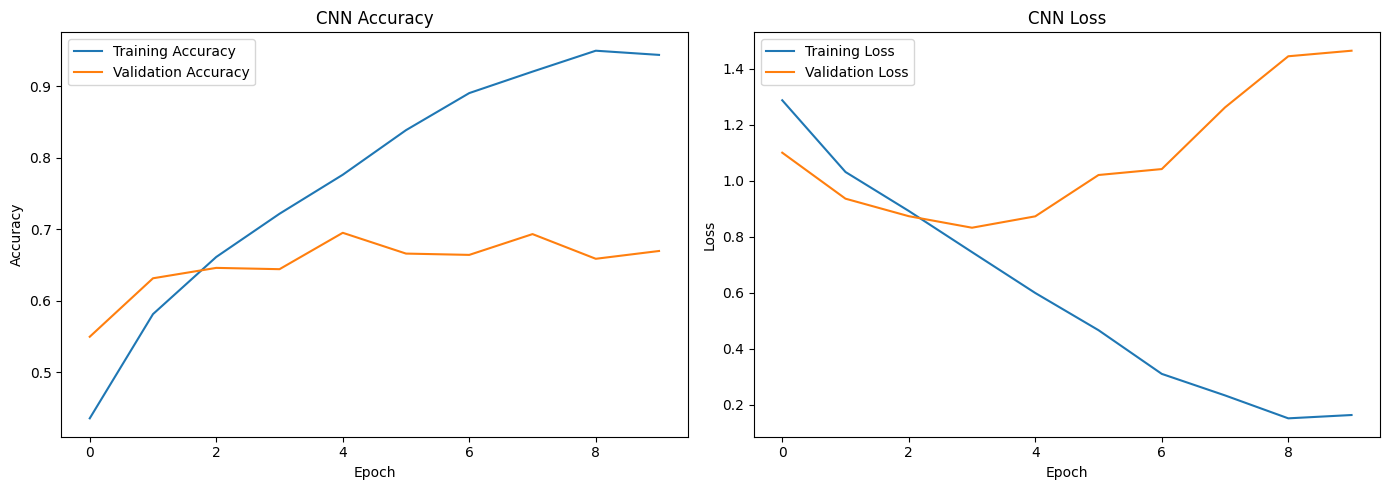

In [ ]:

# CELL 10: Training and validation graphs

plt.figure(figsize=(14,5))

plt.subplot(1,2,1)

plt.plot(cnn_history.history['accuracy'], label='Training Accuracy')
plt.plot(cnn_history.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1,2,2)

plt.plot(cnn_history.history['loss'], label='Training Loss')
plt.plot(cnn_history.history['val_loss'], label='Validation Loss')

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:

# CELL 11: CNN test evaluation

cnn_loss, cnn_accuracy = cnn_model.evaluate(test_ds)

print("CNN Test Loss:", cnn_loss)
print("CNN Test Accuracy:", cnn_accuracy)


18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.7055 - loss: 1.2904
CNN Test Loss: 1.2903856039047241
CNN Test Accuracy: 0.7054545283317566


In [ ]:

# CELL 12: Load pretrained MobileNetV2

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

print("Pretrained model loaded!")
print("Total layers:", len(base_model.layers))


Pretrained model loaded!
Total layers: 154


In [ ]:

# CELL 13: Freeze MobileNetV2

base_model.trainable = False

print("Base model frozen!")

print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))


Base model frozen!
Trainable layers: 0


In [ ]:

# CELL 14: Build transfer learning model

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomContrast(0.15)
])

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Augmentation only during training
x = data_augmentation(inputs)

# MobileNetV2 preprocessing: pixels from 0-255 to -1 to 1
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Extract pretrained features
x = base_model(x, training=False)

# Reduce spatial dimensions
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Regularization
x = tf.keras.layers.Dropout(0.3)(x)

# Our five-class classifier
outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation='softmax'
)(x)

transfer_model = tf.keras.Model(inputs, outputs)

transfer_model.summary()


Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_7 (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_3 (TrueDivide)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_3 (Subtract)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

# CELL 15: Compile transfer learning model

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

print("Transfer learning model compiled!")


Transfer learning model compiled!


In [ ]:

# CELL 16: Train feature extraction model

callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        'best_flowervision_model.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks
)


Epoch 1/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.6267 - loss: 1.0120 - val_accuracy: 0.8004 - val_loss: 0.5499 - learning_rate: 0.0010
Epoch 2/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.7980 - loss: 0.5520 - val_accuracy: 0.8403 - val_loss: 0.4345 - learning_rate: 0.0010
Epoch 3/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.8315 - loss: 0.4540 - val_accuracy: 0.8548 - val_loss: 0.3960 - learning_rate: 0.0010
Epoch 4/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.8427 - loss: 0.4354 - val_accuracy: 0.8693 - val_loss: 0.3794 - learning_rate: 0.0010
Epoch 5/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.8529 - loss: 0.3959 - val_accuracy: 0.8639 - val_loss: 0.3554 - learning_rate: 0.0010
Epoch 6/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.8727 - loss: 0.3526 - val_accuracy: 0.8730 - val_loss: 0.3449 - learning_rate: 0.0010
Epoch 7/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.8669 - loss: 0.3456 - val_ac

In [ ]:

# CELL 17: Fine-tuning

base_model.trainable = True

# Freeze all except the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

# Recompile after changing trainable layers
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

fine_tune_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)


Trainable layers: 19
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 12s 75ms/step - accuracy: 0.8976 - loss: 0.2831 - val_accuracy: 0.8784 - val_loss: 0.3100 - learning_rate: 1.0000e-05
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 55ms/step - accuracy: 0.9007 - loss: 0.2632 - val_accuracy: 0.8911 - val_loss: 0.2998 - learning_rate: 1.0000e-05
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.9163 - loss: 0.2380 - val_accuracy: 0.8984 - val_loss: 0.2839 - learning_rate: 1.0000e-05
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.9105 - loss: 0.2297 - val_accuracy: 0.8929 - val_loss: 0.2863 - learning_rate: 1.0000e-05
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9221 - loss: 0.2134 - val_accuracy: 0.8929 - val_loss: 0.2806 - learning_rate: 1.0000e-05
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.9264 - loss: 0.2075 - val_accuracy: 0.8929 - val_loss: 0.2816 - learning_rate: 1.0000e-05
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - ac

In [ ]:

# CELL 18: Evaluate both models

cnn_results = cnn_model.evaluate(test_ds, verbose=0)

transfer_results = transfer_model.evaluate(test_ds, verbose=0)

comparison = pd.DataFrame({
    "Model": ["CNN From Scratch", "MobileNetV2 Transfer Learning"],
    "Test Loss": [cnn_results[0], transfer_results[0]],
    "Test Accuracy": [cnn_results[1], transfer_results[1]]
})

print(comparison)


                           Model  Test Loss  Test Accuracy
0               CNN From Scratch   1.290386       0.705455
1  MobileNetV2 Transfer Learning   0.233952       0.920000


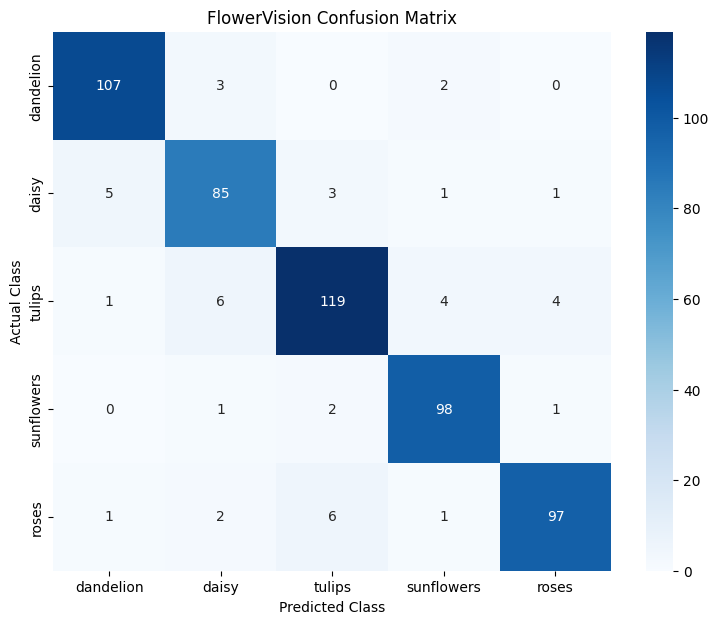

In [ ]:

# CELL 19: Confusion matrix

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = transfer_model.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9,7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("FlowerVision Confusion Matrix")

plt.show()


In [ ]:

# CELL 20: Classification report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)


              precision    recall  f1-score   support

   dandelion     0.9386    0.9554    0.9469       112
       daisy     0.8763    0.8947    0.8854        95
      tulips     0.9154    0.8881    0.9015       134
  sunflowers     0.9245    0.9608    0.9423       102
       roses     0.9417    0.9065    0.9238       107

    accuracy                         0.9200       550
   macro avg     0.9193    0.9211    0.9200       550
weighted avg     0.9202    0.9200    0.9199       550



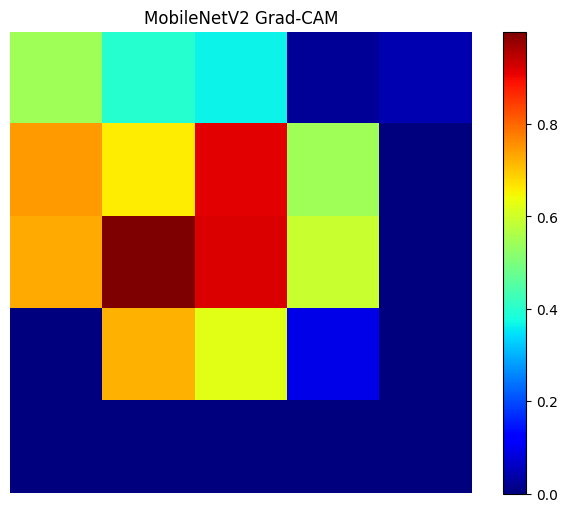

Grad-CAM generated successfully!


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

def make_gradcam_heatmap(img_array, model):

    augmentation = model.get_layer("sequential_7")

    backbone = model.get_layer("mobilenetv2_1.00_160")

    gap = model.get_layer("global_average_pooling2d_3")
    dropout = model.get_layer("dropout_7")
    classifier = model.get_layer("dense_11")

    feature_extractor = tf.keras.Model(
        inputs=backbone.input,
        outputs=backbone.get_layer("out_relu").output
    )

    with tf.GradientTape() as tape:

        x = augmentation(img_array, training=False)

        # MobileNetV2 preprocessing
        x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

        conv_outputs = feature_extractor(x, training=False)

        tape.watch(conv_outputs)

        features = gap(conv_outputs)
        features = dropout(features, training=False)
        predictions = classifier(features)

        class_index = tf.argmax(predictions[0])
        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)

    if gradients is None:
        raise ValueError("Gradients are disconnected.")

    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(conv_outputs * weights, axis=-1)

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()


# Generate Grad-CAM

sample_image = sample_images[0:1]

heatmap = make_gradcam_heatmap(sample_image, transfer_model)

# Display

plt.figure(figsize=(8, 6))
plt.imshow(heatmap, cmap="jet")
plt.title("MobileNetV2 Grad-CAM")
plt.colorbar()
plt.axis("off")
plt.show()

print("Grad-CAM generated successfully!")


Saving romantic-blooms-red-rose-background-free-photo.jpg to romantic-blooms-red-rose-background-free-photo.jpg


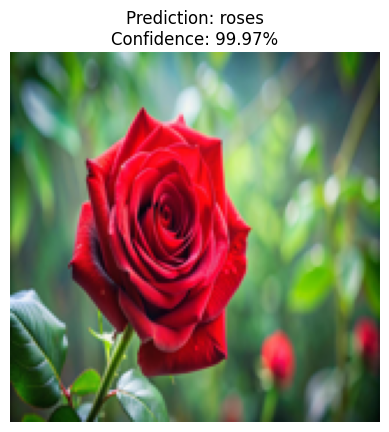

Prediction: roses
Confidence: 99.97%

Class probabilities:
dandelion: 0.00%
daisy: 0.00%
tulips: 0.03%
sunflowers: 0.00%
roses: 99.97%


In [ ]:

# CELL 22: Upload your own image

from google.colab import files
from PIL import Image

uploaded = files.upload()

for filename in uploaded.keys():

    image = Image.open(filename).convert("RGB")

    image = image.resize((IMG_SIZE, IMG_SIZE))

    image_array = np.array(image).astype("float32")

    image_batch = np.expand_dims(image_array, axis=0)

    probabilities = transfer_model.predict(
        image_batch,
        verbose=0
    )[0]

    predicted_index = np.argmax(probabilities)

    predicted_flower = CLASS_NAMES[predicted_index]

    confidence = probabilities[predicted_index] * 100

    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_flower}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Prediction:", predicted_flower)
    print("Confidence:", f"{confidence:.2f}%")

    print("\nClass probabilities:")

    for name, probability in zip(CLASS_NAMES, probabilities):
        print(f"{name}: {probability*100:.2f}%")


In [ ]:

# CELL 23: Save model

transfer_model.save("FlowerVision_Final.keras")

print("Model saved successfully!")


Model saved successfully!


In [ ]:

# CELL 24: Download trained model

from google.colab import files

files.download("FlowerVision_Final.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
loaded_model = tf.keras.models.load_model(
    "FlowerVision_Final.keras"
)


       MOBILENETV2 PERFORMANCE REPORT
Test Accuracy : 92.00%
Test Loss     : 0.2340
Precision     : 92.02%
Recall        : 92.00%
F1 Score      : 91.99%

Total Test Samples: 550
Correct Predictions: 506
Incorrect Predictions: 44

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       112
           1       0.88      0.89      0.89        95
           2       0.92      0.89      0.90       134
           3       0.92      0.96      0.94       102
           4       0.94      0.91      0.92       107

    accuracy                           0.92       550
   macro avg       0.92      0.92      0.92       550
weighted avg       0.92      0.92      0.92       550



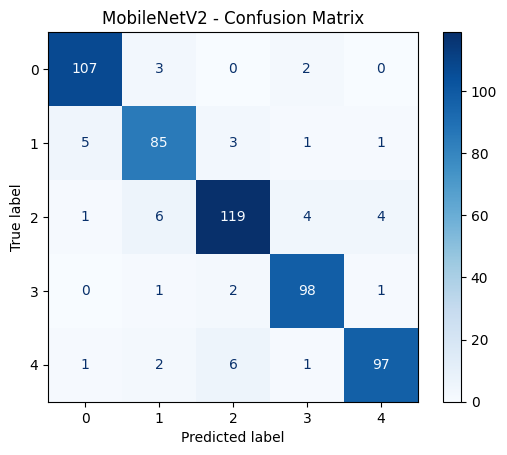

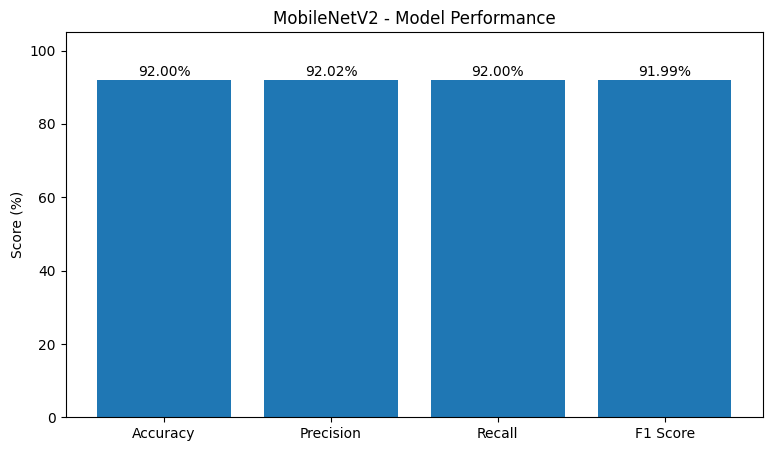


Model evaluation completed successfully!


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================
# 1. EVALUATE MODEL
# ==========================================

test_loss, test_accuracy = transfer_model.evaluate(
    test_ds,
    verbose=0
)

# ==========================================
# 2. GENERATE PREDICTIONS
# ==========================================

y_true = []
y_pred = []

for batch_images, batch_labels in test_ds:

    predictions = transfer_model.predict(
        batch_images,
        verbose=0
    )

    y_true.extend(batch_labels.numpy().reshape(-1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true).astype(int)
y_pred = np.array(y_pred).astype(int)

# ==========================================
# 3. CALCULATE METRICS
# ==========================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# ==========================================
# 4. PRINT PERFORMANCE REPORT
# ==========================================

print("\n" + "=" * 55)
print("       MOBILENETV2 PERFORMANCE REPORT")
print("=" * 55)

print(f"Test Accuracy : {accuracy * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Precision     : {precision * 100:.2f}%")
print(f"Recall        : {recall * 100:.2f}%")
print(f"F1 Score      : {f1 * 100:.2f}%")

print(f"\nTotal Test Samples: {len(y_true)}")
print(f"Correct Predictions: {np.sum(y_true == y_pred)}")
print(f"Incorrect Predictions: {np.sum(y_true != y_pred)}")

print("\nCLASSIFICATION REPORT")
print("=" * 55)

print(classification_report(
    y_true,
    y_pred,
    zero_division=0
))

# ==========================================
# 5. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MobileNetV2 - Confusion Matrix")
plt.show()

# ==========================================
# 6. PERFORMANCE VISUALIZATION
# ==========================================

metrics = {
    "Accuracy": accuracy * 100,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1 Score": f1 * 100
}

plt.figure(figsize=(9, 5))

bars = plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.ylim(0, 105)
plt.ylabel("Score (%)")
plt.title("MobileNetV2 - Model Performance")

for bar, value in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

print("\nModel evaluation completed successfully!")
